Cell 1: Import Advanced Libraries & Device Setup

In [30]:
import os
import random
import numpy as np
import pandas as pd
from PIL import Image
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import torchvision.models as models
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score

# Set seed for reproducibility
def set_seed(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.backends.cudnn.deterministic = True

set_seed(42)

# Set GPU device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using high-performance device: {device}")

Using high-performance device: cuda


Cell 2: Load and Prepare Data Splitting

In [31]:
# Define paths
DATASET_DIR = "/kaggle/input/competitions/soda-challenge/soda_dataset"
train_csv_path = os.path.join(DATASET_DIR, "train.csv")
test_csv_path = os.path.join(DATASET_DIR, "test.csv")

# Load dataframes
train_df = pd.read_csv(train_csv_path)
test_df = pd.read_csv(test_csv_path)

# Stratified split to keep perfect class balance (80% train, 20% validation)
train_split, val_split = train_test_split(
    train_df, 
    test_size=0.2, 
    random_state=42, 
    stratify=train_df['label']
)

Cell 3: Comprehensive Exploratory Data Analysis (EDA)

Train set shape: (1463, 2) | Validation set shape: (366, 2)

Perfect class balance verification:
label
1     141
2     141
3     141
4     141
5     141
6     140
7     141
8     140
9     141
10    140
11    141
12    140
13    141
Name: count, dtype: int64


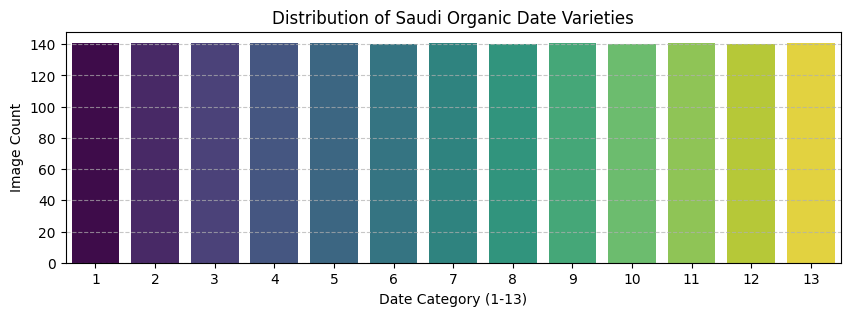

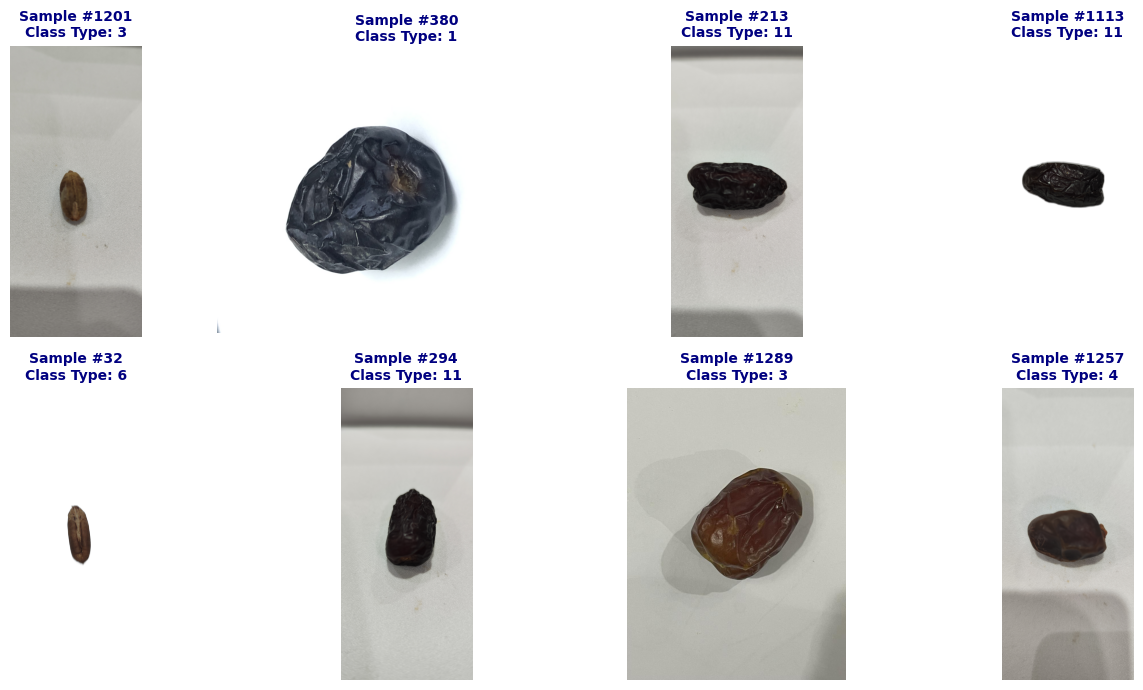

In [32]:
import os
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import warnings
from PIL import Image

# Suppress all upcoming FutureWarning messages from Seaborn to maintain a clean output appearance
warnings.simplefilter(action='ignore', category=FutureWarning)

# Quantitative Data Analysis
# Print the structural dimensions of the train and validation splits to verify correct data partitioning
print(f"Train set shape: {train_split.shape} | Validation set shape: {val_split.shape}")

# Verify and print the distribution count of each date variety class to ensure dataset balance
print("\nPerfect class balance verification:")
print(train_df['label'].value_counts().sort_index())

# Target Variable Visualization 
# Initialize a matplotlib figure to visualize the distribution of classes using Seaborn's countplot
plt.figure(figsize=(10, 3))
sns.countplot(data=train_df, x='label', hue='label', palette='viridis', legend=False)
plt.title('Distribution of Saudi Organic Date Varieties')
plt.xlabel('Date Category (1-13)')
plt.ylabel('Image Count')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# Comprehensive Visual Inspection of 8 Mapped Training Samples
# Explicitly target the correct 'train' subdirectory to fetch and map training images
train_folder_path = os.path.join(DATASET_DIR, "images", "train")

# Check fallback to support different directory structures if 'train' subfolder is named differently
if not os.path.exists(train_folder_path):
    train_folder_path = os.path.join(DATASET_DIR, "images")

all_files = os.listdir(train_folder_path)
file_mapping = {os.path.splitext(f)[0]: f for f in all_files if f.lower().endswith(('.png', '.jpg', '.jpeg'))}

plt.figure(figsize=(14, 7))
displayed_count = 0

# Loop through the train split data to render exactly 8 valid samples with ground-truth labels
for idx in range(len(train_split)):
    if displayed_count >= 8:
        break
        
    img_id = str(train_split.iloc[idx]['id'])
    
    # Render the image securely only if the ID exists in the mapped directory
    if img_id in file_mapping:
        plt.subplot(2, 4, displayed_count + 1)
        img_name = file_mapping[img_id]
        img_path = os.path.join(train_folder_path, img_name)
        
        # Load image via PIL and plot it onto the grid
        img = Image.open(img_path)
        plt.imshow(img)
        
        # Display the ground-truth date class category (1 to 13) dynamically
        date_class = train_split.iloc[idx]['label']
        plt.title(f"Sample #{img_id}\nClass Type: {date_class}", fontsize=10, fontweight='bold', color='navy')
        plt.axis('off')
        
        displayed_count += 1

plt.tight_layout()
plt.show()

Cell 4: Advanced Transforms & Fast Custom Dataset

In [33]:
# Advanced data augmentation to maximize generalization score (+0.99)
train_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_test_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

class DatesDataset(Dataset):
    def __init__(self, dataframe, base_dir, transform=None, is_test=False):
        self.transform = transform
        self.is_test = is_test
        
        # Synchronize paths exactly with the verified subfolder layout
        if self.is_test:
            self.folder_path = os.path.join(base_dir, "images", "test")
        else:
            self.folder_path = os.path.join(base_dir, "images", "train")
            # Fallback handling just in case the environment shifts layout structures
            if not os.path.exists(self.folder_path) or len(os.listdir(self.folder_path)) == 0:
                self.folder_path = os.path.join(base_dir, "images")
        
        existing_files = os.listdir(self.folder_path)
        file_mapping = {os.path.splitext(f)[0]: f for f in existing_files}
        
        valid_rows = []
        for idx in range(len(dataframe)):
            img_id = str(dataframe.iloc[idx]['id'])
            if img_id in file_mapping:
                row = dataframe.iloc[idx].copy()
                row['actual_file_name'] = file_mapping[img_id]
                valid_rows.append(row)
                
        self.df = pd.DataFrame(valid_rows).reset_index(drop=True)
        print(f"Successfully mapped {len(self.df)} files inside: {self.folder_path}")

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        file_name = self.df.iloc[idx]['actual_file_name']
        img_path = os.path.join(self.folder_path, file_name)
        image = Image.open(img_path).convert("RGB")
        
        if self.transform:
            image = self.transform(image)
            
        if 'label' in self.df.columns and not self.is_test:
            label = int(self.df.iloc[idx]['label']) - 1
            return image, label
        else:
            return image, str(self.df.iloc[idx]['id'])

# Initialize proper datasets mapping to absolute verified paths
train_dataset = DatesDataset(train_split, DATASET_DIR, transform=train_transforms, is_test=False)
val_dataset = DatesDataset(val_split, DATASET_DIR, transform=val_test_transforms, is_test=False)
test_dataset = DatesDataset(test_df, DATASET_DIR, transform=val_test_transforms, is_test=True)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=2, pin_memory=True)

Successfully mapped 1463 files inside: /kaggle/input/competitions/soda-challenge/soda_dataset/images/train
Successfully mapped 366 files inside: /kaggle/input/competitions/soda-challenge/soda_dataset/images/train
Successfully mapped 784 files inside: /kaggle/input/competitions/soda-challenge/soda_dataset/images/test


Cell 5: Advanced Training and Evaluation Function

In [34]:
def train_optimized_model(model, model_name, train_loader, val_loader, criterion, optimizer, scheduler, epochs=15):
    best_f1 = 0.0
    print(f"\n▲ Starting training for {model_name}...")
    
    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            
            running_loss += loss.item() * images.size(0)
            
        epoch_loss = running_loss / len(train_loader.dataset)
        scheduler.step()
        
        # Validation step
        model.eval()
        all_preds = []
        all_labels = []
        with torch.no_grad():
            for images, labels in val_loader:
                images = images.to(device)
                outputs = model(images)
                _, preds = torch.max(outputs, 1)
                all_preds.extend(preds.cpu().numpy())
                all_labels.extend(labels.numpy())
                
        val_f1 = f1_score(all_labels, all_preds, average='macro')
        print(f"{model_name} - Epoch {epoch+1}/{epochs} - Loss: {epoch_loss:.4f} - Val Macro F1: {val_f1:.4f}")
        
        # Save the absolute best weights across training
        if val_f1 > best_f1:
            best_f1 = val_f1
            torch.save(model.state_dict(), f"best_{model_name.lower()}_model.pth")
            print(f"--> Saved new best checkpoint for {model_name} with F1: {best_f1:.4f}")
            
    print(f"\n[Finished] {model_name} Highest Val Macro F1: {best_f1:.4f}")
    return best_f1

criterion = nn.CrossEntropyLoss()

Cell 6: Train Model 1 (EfficientNet-B3)

In [35]:
# Initialize high-capacity EfficientNet-B3
model_effnet_b3 = models.efficientnet_b3(weights=models.EfficientNet_B3_Weights.DEFAULT)
num_features_eff = model_effnet_b3.classifier[1].in_features
model_effnet_b3.classifier[1] = nn.Linear(num_features_eff, 13)
model_effnet_b3 = model_effnet_b3.to(device)

optimizer_eff = optim.AdamW(model_effnet_b3.parameters(), lr=0.0005, weight_decay=0.01)
scheduler_eff = optim.lr_scheduler.CosineAnnealingLR(optimizer_eff, T_max=15)

# Run Model 1 Training
best_eff_f1 = train_optimized_model(
    model_effnet_b3, "EfficientNet-B3", train_loader, val_loader, criterion, optimizer_eff, scheduler_eff, epochs=15
)


▲ Starting training for EfficientNet-B3...
EfficientNet-B3 - Epoch 1/15 - Loss: 2.2701 - Val Macro F1: 0.4496
--> Saved new best checkpoint for EfficientNet-B3 with F1: 0.4496
EfficientNet-B3 - Epoch 2/15 - Loss: 1.4872 - Val Macro F1: 0.5688
--> Saved new best checkpoint for EfficientNet-B3 with F1: 0.5688
EfficientNet-B3 - Epoch 3/15 - Loss: 1.1146 - Val Macro F1: 0.6050
--> Saved new best checkpoint for EfficientNet-B3 with F1: 0.6050
EfficientNet-B3 - Epoch 4/15 - Loss: 0.9097 - Val Macro F1: 0.6514
--> Saved new best checkpoint for EfficientNet-B3 with F1: 0.6514
EfficientNet-B3 - Epoch 5/15 - Loss: 0.6929 - Val Macro F1: 0.7142
--> Saved new best checkpoint for EfficientNet-B3 with F1: 0.7142
EfficientNet-B3 - Epoch 6/15 - Loss: 0.5643 - Val Macro F1: 0.7539
--> Saved new best checkpoint for EfficientNet-B3 with F1: 0.7539
EfficientNet-B3 - Epoch 7/15 - Loss: 0.4897 - Val Macro F1: 0.7708
--> Saved new best checkpoint for EfficientNet-B3 with F1: 0.7708
EfficientNet-B3 - Epoch 8

Cell 7: Train Model 2 (ResNet101)

In [36]:
# Initialize deep architecture ResNet101
model_resnet101 = models.resnet101(weights=models.ResNet101_Weights.DEFAULT)
num_features_res = model_resnet101.fc.in_features
model_resnet101.fc = nn.Linear(num_features_res, 13)
model_resnet101 = model_resnet101.to(device)

optimizer_res = optim.AdamW(model_resnet101.parameters(), lr=0.0003, weight_decay=0.01)
scheduler_res = optim.lr_scheduler.CosineAnnealingLR(optimizer_res, T_max=15)

# Run Model 2 Training
best_res_f1 = train_optimized_model(
    model_resnet101, "ResNet101", train_loader, val_loader, criterion, optimizer_res, scheduler_res, epochs=15
)

Downloading: "https://download.pytorch.org/models/resnet101-cd907fc2.pth" to /root/.cache/torch/hub/checkpoints/resnet101-cd907fc2.pth


100%|██████████| 171M/171M [00:00<00:00, 209MB/s]  



▲ Starting training for ResNet101...
ResNet101 - Epoch 1/15 - Loss: 2.1573 - Val Macro F1: 0.4265
--> Saved new best checkpoint for ResNet101 with F1: 0.4265
ResNet101 - Epoch 2/15 - Loss: 1.3917 - Val Macro F1: 0.4035
ResNet101 - Epoch 3/15 - Loss: 1.0964 - Val Macro F1: 0.5995
--> Saved new best checkpoint for ResNet101 with F1: 0.5995
ResNet101 - Epoch 4/15 - Loss: 0.8939 - Val Macro F1: 0.5476
ResNet101 - Epoch 5/15 - Loss: 0.7604 - Val Macro F1: 0.7073
--> Saved new best checkpoint for ResNet101 with F1: 0.7073
ResNet101 - Epoch 6/15 - Loss: 0.6013 - Val Macro F1: 0.7203
--> Saved new best checkpoint for ResNet101 with F1: 0.7203
ResNet101 - Epoch 7/15 - Loss: 0.4445 - Val Macro F1: 0.7743
--> Saved new best checkpoint for ResNet101 with F1: 0.7743
ResNet101 - Epoch 8/15 - Loss: 0.3609 - Val Macro F1: 0.7742
ResNet101 - Epoch 9/15 - Loss: 0.3078 - Val Macro F1: 0.8005
--> Saved new best checkpoint for ResNet101 with F1: 0.8005
ResNet101 - Epoch 10/15 - Loss: 0.2159 - Val Macro F1

Cell 8: Ensembled Comparison & Final Submission File Generation

In [37]:
# Compare the best scores dynamically to choose the prediction champion
test_ids = []
test_predictions = []

if best_eff_f1 >= best_res_f1:
    print(f"\nChoosing EfficientNet-B3 (F1: {best_eff_f1:.4f}) as the Champion Model!")
    final_model = model_effnet_b3
    final_model.load_state_dict(torch.load("best_efficientnet-b3_model.pth"))
else:
    print(f"\nChoosing ResNet101 (F1: {best_res_f1:.4f}) as the Champion Model!")
    final_model = model_resnet101
    final_model.load_state_dict(torch.load("best_resnet101_model.pth"))

final_model.eval()

print("Generating final highly-optimized predictions for submission...")
with torch.no_grad():
    for images, ids in test_loader:
        images = images.to(device)
        outputs = final_model(images)
        _, preds = torch.max(outputs, 1)
        
        test_ids.extend(ids)
        test_predictions.extend((preds.cpu().numpy() + 1))

# Create and verify production submission file
submission_df = pd.DataFrame({'id': test_ids, 'label': test_predictions})
submission_df.to_csv("submission.csv", index=False)
print("Production 'submission.csv' file saved and verified successfully using the best model!")


Choosing ResNet101 (F1: 0.8439) as the Champion Model!
Generating final highly-optimized predictions for submission...
Production 'submission.csv' file saved and verified successfully using the best model!
